Split already exists
Using device: cpu
Classes: ['Normal', 'high_risk', 'low_risk', 'moderate']
Epoch 1, Loss: 219.40, Val Acc: 0.6041
Epoch 2, Loss: 116.56, Val Acc: 0.6754
Epoch 3, Loss: 109.04, Val Acc: 0.6492
Epoch 4, Loss: 104.50, Val Acc: 0.6567
Epoch 5, Loss: 104.20, Val Acc: 0.6923
Epoch 6, Loss: 101.15, Val Acc: 0.6417
Epoch 7, Loss: 102.34, Val Acc: 0.7205
Epoch 8, Loss: 96.78, Val Acc: 0.7054
Epoch 9, Loss: 94.54, Val Acc: 0.7598
Epoch 10, Loss: 96.10, Val Acc: 0.7392

TRAIN REPORT:

              precision    recall  f1-score   support

      Normal       0.91      0.96      0.93       380
   high_risk       0.75      0.60      0.66       373
    low_risk       0.89      0.70      0.79       595
    moderate       0.56      0.75      0.64       520

    accuracy                           0.75      1868
   macro avg       0.78      0.75      0.76      1868
weighted avg       0.77      0.75      0.75      1868


TEST REPORT:

              precision    recall  f1-score   supp

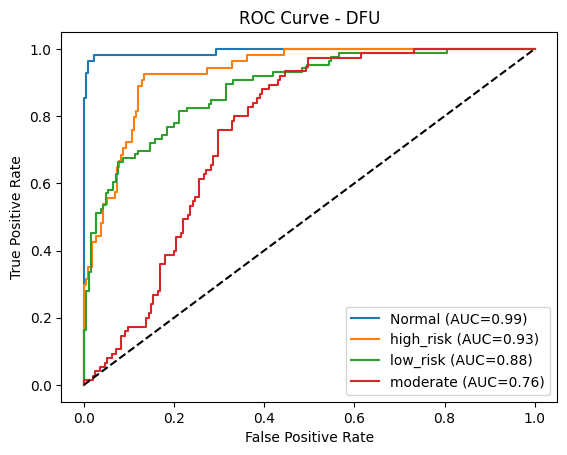

In [1]:
import os
import random
import shutil
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

# -------------------------
# 1. PATHS
# -------------------------
source_dir = "D:/Dia Foot/DFU/Classification Folder"
split_dir = "D:/Dia Foot/DFU/DFU_split"

# -------------------------
# 2. SPLIT DATA (70/20/10)
# -------------------------
if not os.path.exists(split_dir):
    print("Splitting dataset...")

    for cls in os.listdir(source_dir):
        images = os.listdir(os.path.join(source_dir, cls))
        random.shuffle(images)

        n = len(images)
        train_split = int(0.7 * n)
        val_split = int(0.9 * n)

        splits = {
            "train": images[:train_split],
            "val": images[train_split:val_split],
            "test": images[val_split:]
        }

        for split in splits:
            path = os.path.join(split_dir, split, cls)
            os.makedirs(path, exist_ok=True)

            for img in splits[split]:
                shutil.copy(
                    os.path.join(source_dir, cls, img),
                    os.path.join(path, img)
                )

    print("Dataset split done!")
else:
    print("Split already exists")

# -------------------------
# 3. DEVICE
# -------------------------
device = torch.device("cpu")
print("Using device:", device)

# -------------------------
# 4. TRANSFORMS (NORMALIZATION)
# -------------------------
transform_train = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

# -------------------------
# 5. LOAD DATA
# -------------------------
train_data = datasets.ImageFolder(split_dir + "/train", transform=transform_train)
val_data   = datasets.ImageFolder(split_dir + "/val", transform=transform_val)
test_data  = datasets.ImageFolder(split_dir + "/test", transform=transform_val)

train_loader = DataLoader(train_data, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_data, batch_size=16, shuffle=False)
test_loader  = DataLoader(test_data, batch_size=16, shuffle=False)

class_names = train_data.classes
print("Classes:", class_names)

# -------------------------
# 6. CNN MODEL
# -------------------------
class DFU_CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 4)
        )

    def forward(self, x):
        return self.fc(self.conv(x))

model = DFU_CNN().to(device)

# -------------------------
# 7. LOSS + OPTIMIZER
# -------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# -------------------------
# 8. TRAINING
# -------------------------
epochs = 10
best_val_acc = 0

for epoch in range(epochs):
    model.train()
    train_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # VALIDATION
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_acc = correct / total
    print(f"Epoch {epoch+1}, Loss: {train_loss:.2f}, Val Acc: {val_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_dfu_model.pth")

# -------------------------
# 9. TRAIN REPORT
# -------------------------
model.eval()
train_preds, train_labels = [], []

with torch.no_grad():
    for images, labels in train_loader:
        outputs = model(images.to(device))
        _, preds = torch.max(outputs, 1)

        train_preds.extend(preds.cpu().numpy())
        train_labels.extend(labels.numpy())

print("\nTRAIN REPORT:\n")
print(classification_report(train_labels, train_preds, target_names=class_names))

# -------------------------
# 10. TEST REPORT
# -------------------------
model.load_state_dict(torch.load("best_dfu_model.pth"))
model.eval()

all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        probs = torch.softmax(outputs, dim=1)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

print("\nTEST REPORT:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

# -------------------------
# 11. ROC + AUC
# -------------------------
y_true = np.array(all_labels)
y_score = np.array(all_probs)

y_true_bin = label_binarize(y_true, classes=[0,1,2,3])

plt.figure()

for i in range(4):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - DFU")
plt.legend()
plt.show()